In [63]:
import torch
import numpy as np
from torch_geometric.nn import MessagePassing
import matplotlib.pyplot as plt


class FVM_HodgkinHuxley(MessagePassing):
    def __init__(self):
        super().__init__(aggr='add')

    ## Internal class functions,
    ## These are used to define the alpha and beta functions
    @staticmethod
    def _rate_fractional(v, A, V_shift, K, eps):
        return A * (v + V_shift) / (1.0 - torch.exp(-(v + V_shift) / K) + eps)

    @staticmethod
    def _rate_exponential(v, A, V_shift, K):
        return A * torch.exp(-(v + V_shift) / K)

    @staticmethod
    def _rate_inverse_sigmoid(v, A, V_shift, K):
        return A / (1.0 + torch.exp(-(v + V_shift) / K))

    # forward() triggers message, aggregate, and update sequentially
    # 1. message() used differences in voltage between adjacent nodes to calculate what the
    #   ion flow should be. The results are passed as messages.
    # 2. In aggregate(), each noted takes in the message/current and updaets its coltage accordingly
    # 3. In update(), ion flow through the membrane is determined and voltage calculated
    def forward(self, V, gating_vars, edge_index, g_axial, params, I_ext):
        return self.propagate(edge_index, x=V, gating_vars=gating_vars, g_axial=g_axial, p=params, I_ext=I_ext)

    def message(self, x_i, x_j, g_axial):
        # Calculates ion flux between adjacent nodes
        return g_axial * (x_j - x_i)


    def update(self, aggr_out, x, gating_vars, p, I_ext):
            # Unpack the gating variables from gating_vars
            m, h, n = gating_vars.split(1, dim=1)

            # Unpack parameter tuples directly into the static methods
            alpha_m = self._rate_fractional(x, *p['alpha_m'])
            beta_m  = self._rate_exponential(x, *p['beta_m'])

            alpha_h = self._rate_exponential(x, *p['alpha_h'])
            beta_h  = self._rate_inverse_sigmoid(x, *p['beta_h'])

            alpha_n = self._rate_fractional(x, *p['alpha_n'])
            beta_n  = self._rate_exponential(x, *p['beta_n'])

            # Gating derivatives
            dm_dt = alpha_m * (1.0 - m) - beta_m * m
            dh_dt = alpha_h * (1.0 - h) - beta_h * h
            dn_dt = alpha_n * (1.0 - n) - beta_n * n

            # Ionic currents
            I_Na   = p['g_Na'] * (m**3) * h * (x - p['E_Na'])
            I_K    = p['g_K']  * (n**4) *     (x - p['E_K'])
            I_Leak = p['g_L']  *              (x - p['E_L'])

            # Voltage derivative with axial flux (aggr_out) included
            dV_dt = (I_ext - I_Na - I_K - I_Leak + aggr_out) / p['C_m']
            dgating_dt = torch.cat([dm_dt, dh_dt, dn_dt], dim=1)

            return dV_dt, dgating_dt


In [ ]:
## Initialize the model and parameters, current design tries to stay stateless
HH_PARAMS = {
    # Tuples ordered as: (A, V_shift, K, [eps])
    'alpha_m': (0.1, 40.0, 10.0, 1e-8),
    'beta_m':  (4.0, 65.0, 18.0),
    'alpha_h': (0.07, 65.0, 20.0),
    'beta_h':  (1.0, 35.0, 10.0),
    'alpha_n': (0.01, 55.0, 10.0, 1e-8),
    'beta_n':  (0.125, 65.0, 80.0),
    'g_Na': 120.0, 'E_Na': 50.0,
    'g_K': 36.0,   'E_K': -77.0,
    'g_L': 0.3,    'E_L': -54.387,
    'C_m': 1.0
}

# Simulation parameters:
dt = 0.01
t_max = 50.0  # ms
steps = int(t_max / dt)

num_nodes = 100
axon_length = 1.0 # cm
dx = axon_length / num_nodes # distance between centers of nodes
axon_radius = 0.0238 # cm. convert to um?
Ri = 35.4 # ohm*cm
membrane_area = 1.49 * 10**-1 # cm^2

# Build the graph. Forward first, then reversed so that the connections are bidirectional.
forward_edges = [[i, i+1] for i in range(num_nodes - 1)]
edges = forward_edges + [[dst, src] for src, dst in forward_edges]

## Convert list to tensor, transpose to [2, num_edges], and make contiguous in memory
edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()

# Axial conductance between compartments
#g_axial = torch.full((edge_index.size(1), 1), 2.0)
g_axial = (axon_radius * 1000 ) / (2 * Ri * dx**2)

# initialize the solver and variables that will store the output values
FVM_HH_solver = FVM_HodgkinHuxley()

#Initialize state with resting values
V = torch.full((num_nodes, 1), -65.0) # Assumes resting steady-states at -65 mV
m = torch.full((num_nodes, 1), 0.05)
h = torch.full((num_nodes, 1), 0.60)
n = torch.full((num_nodes, 1), 0.32)
gating_vars = torch.cat([m, h, n], dim=1)



# Store the voltages at each step
history_V = {i: [] for i in range(num_nodes)}
history_gating_vars = {i: [] for i in range(num_nodes)}
time_track = []


## solve the model at each time step
for step in range(steps):
    t = step * dt 
    I_ext = torch.zeros((num_nodes, 1))

    # Calculate derivatives
    dV_dt, dgating_dt = FVM_HH_solver(V, gating_vars, edge_index, g_axial, HH_PARAMS, I_ext)

    # Euler integration, determining updated voltages
    V = V + dV_dt * dt
    gating_vars = gating_vars + dgating_dt * dt

    # Voltage clamp the first 3 nodes to -45.0 mV (20 mV depolarization)
    if 1.0 <= t <= 2.0:
        V[0:3, 0] = -45.0

    # Enforce the absorbing right boundary
    V[-1, 0] = -65.0

    # Record Output at evry 0.01 time step
    if step % 100 == 0:
        time_track.append(t)
        for i in range(num_nodes):
            history_V[i].append(V[i, 0].item())
            history_gating_vars[i].append(gating_vars[i].tolist())


In [ ]:
## Plot membrane potential at 0.602 cm




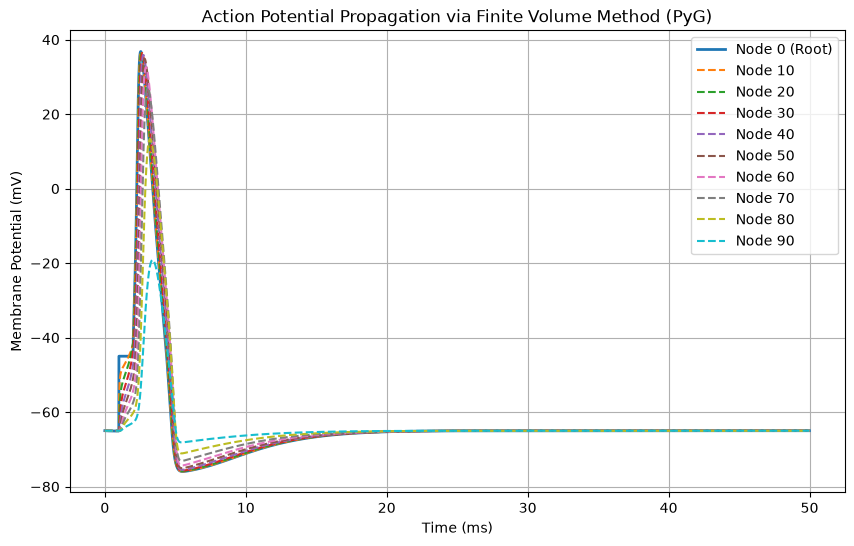

In [ ]:
## Visualization of voltage propogation
plt.figure(figsize=(10, 6))

plt.plot(time_track, history_V[0], label='Node 0 (Root)', linewidth=2)
for v in range(10, 100, 10):
    plt.plot(time_track, history_V[v], label=f'Node {v}', linestyle='--')

plt.title("Action Potential Propagation via Finite Volume Method (PyG)")
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.legend()
plt.grid(True)
plt.show()


In [66]:
## Ionic current densities

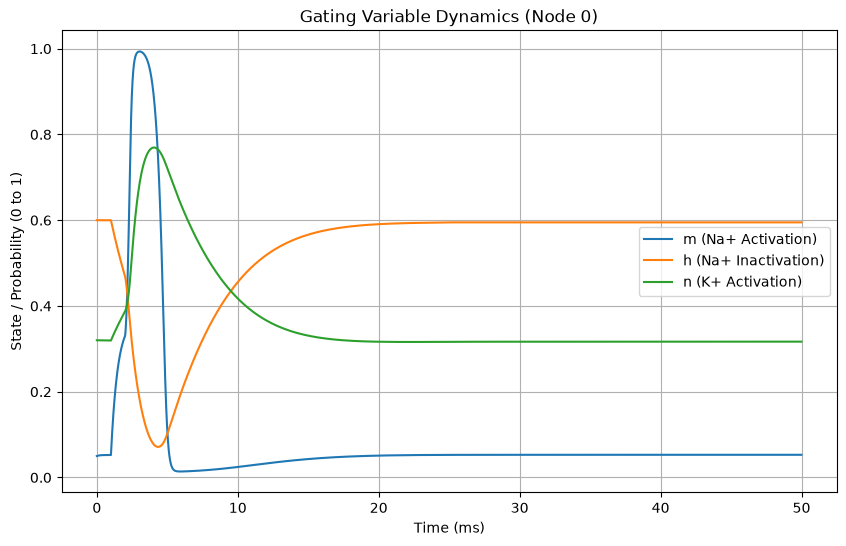

In [69]:
## Gating variables at root:


# 8. Plotting Gating Variables
# Extract m, h, and n traces specifically for Node 0
node_idx = 0
m_trace = [state[0] for state in history_gating_vars[node_idx]]
h_trace = [state[1] for state in history_gating_vars[node_idx]]
n_trace = [state[2] for state in history_gating_vars[node_idx]]

plt.figure(figsize=(10, 6))
plt.plot(time_track, m_trace, label='m (Na+ Activation)')
plt.plot(time_track, h_trace, label='h (Na+ Inactivation)')
plt.plot(time_track, n_trace, label='n (K+ Activation)')

plt.title(f"Gating Variable Dynamics (Node {node_idx})")
plt.xlabel("Time (ms)")
plt.ylabel("State / Probability (0 to 1)")
plt.legend(loc='center right')
plt.grid(True)
plt.show()


In [68]:
## Refractory Period